Hands-On Lab — Classification With the Titanic Dataset

Part 0 — Import Packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

%matplotlib inline
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

Part 1 — Load & Explore the Data 


Task 1 — Load the dataset and inspect its shape, columns, and data types.

In [2]:
df = pd.read_csv('titanic.csv') 
print('Shape:', df.shape) 
df.head() 

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Task 2 — Get summary statistics for the numeric columns. 

In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Task 3 — Check for missing values in every column. 

In [5]:
df.isnull().sum().sort_values(ascending=False)

Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

Observation:  Cabin is missing for the large majority of passengers, Age is missing for 
roughly 20% of passengers, and Embarked is missing for just 2. This tells us Cabin is not 
usable in its raw form, Age needs imputation rather than dropping (we'd lose too much data), 
and Embarked can be filled with its most common value.

Task 4 — Visualize the target variable: how many passengers survived vs. didn't?

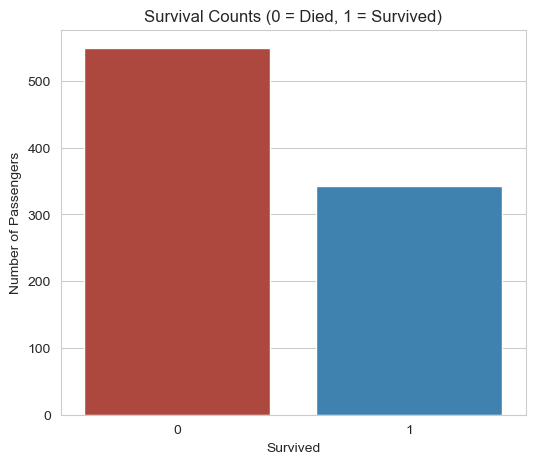

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [6]:
plt.figure(figsize=(6, 5)) 
sns.countplot(x='Survived', data=df, hue='Survived', palette=['#C0392B', '#2E86C1'], legend=False)
plt.title('Survival Counts (0 = Died, 1 = Survived)') 
plt.xlabel('Survived') 
plt.ylabel('Number of Passengers') 
plt.show() 
  
print(df['Survived'].value_counts(normalize=True).round(3))

Observation:  About 62% of passengers in this dataset did not survive and 38% did — the 
classes are imbalanced but not severely, so accuracy alone will still be informative, though 
we'll rely on precision/recall/F1 too for a fuller picture.

Task 5 — Explore how survival relates to Sex, Pclass, and Age.

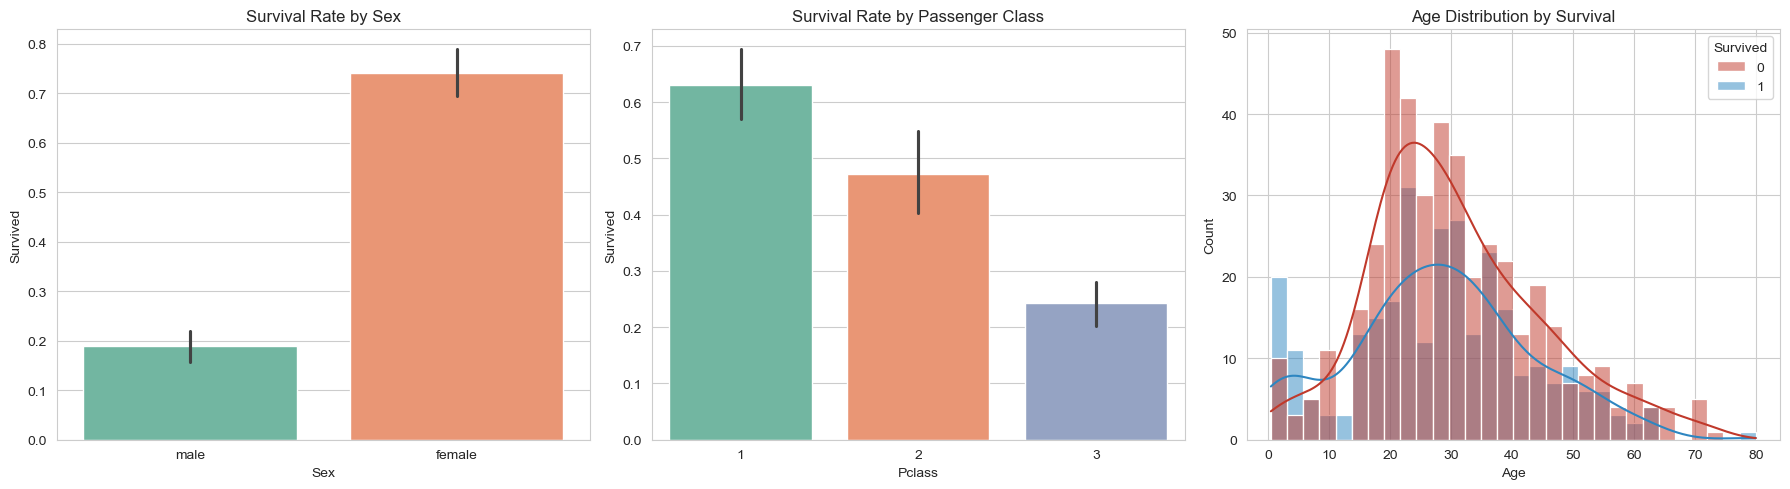

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(x='Sex', y='Survived', data=df, hue='Sex', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Survival Rate by Sex')
sns.barplot(x='Pclass', y='Survived', data=df, hue='Pclass', ax=axes[1], palette='Set2', legend=False)
axes[1].set_title('Survival Rate by Passenger Class')
sns.histplot(data=df, x='Age', hue='Survived', bins=30, kde=True, ax=axes[2],
palette=['#C0392B', '#2E86C1'])
axes[2].set_title('Age Distribution by Survival')

plt.tight_layout()
plt.show()

Observation:  Women had a much higher survival rate than men (the "women and children 
first" evacuation policy), and 1st class passengers survived at a noticeably higher rate than 
2nd or 3rd class — likely reflecting cabin location and lifeboat access. Age alone shows a 
less dramatic split, though very young children show a slightly better survival rate. 

Task 6 — Correlation heatmap of the numeric features. 

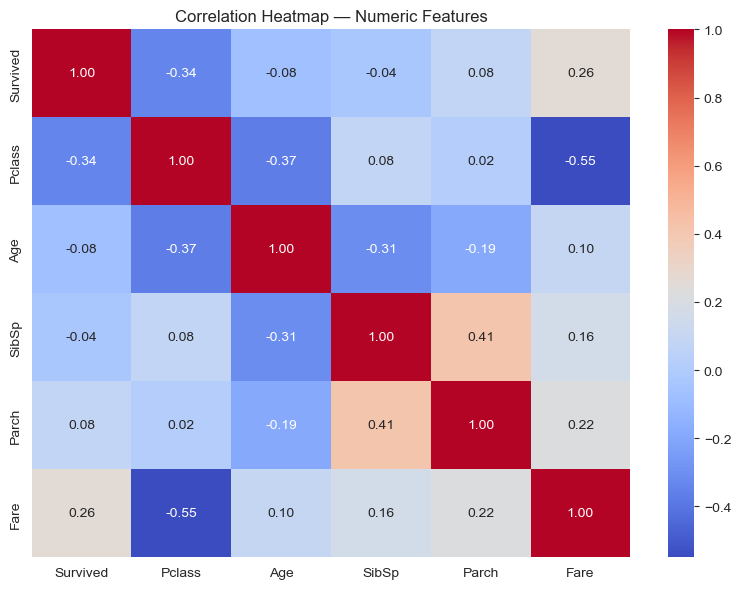

In [8]:
plt.figure(figsize=(8, 6)) 
numeric_df = df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']] 
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f') 
plt.title('Correlation Heatmap — Numeric Features') 
plt.tight_layout() 
plt.show()

Part 2 — Data Cleaning & Feature Engineering 

Task 1 — Fill missing Age values with the median age, and missing Embarked values with the most 
common port. 

In [9]:
df['Age'] = df['Age'].fillna(df['Age'].median()) 
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0]) 
print('Remaining missing Age:', df['Age'].isnull().sum()) 
print('Remaining missing Embarked:', df['Embarked'].isnull().sum())

Remaining missing Age: 0
Remaining missing Embarked: 0


Task 2 — Engineer a FamilySize feature from SibSp (siblings/spouses) and Parch 
(parents/children). 


In [10]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1 
df[['SibSp', 'Parch', 'FamilySize']].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


Task 3 — Drop columns that aren't useful for a numeric classification model: PassengerId, Name, 
Ticket, and Cabin (too many missing values). 

In [11]:
df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1) 
df.columns.tolist() 

['Survived',
 'Pclass',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Fare',
 'Embarked',
 'FamilySize']

Task 4 — Encode the categorical columns (Sex, Embarked) into numbers models can use. 

In [12]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1}) 
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True) 
df.head() 

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,2,False,True
1,1,1,1,38.0,1,0,71.2833,2,False,False
2,1,3,1,26.0,0,0,7.9250,1,False,True
3,1,1,1,35.0,1,0,53.1000,2,False,True
4,0,3,0,35.0,0,0,8.0500,1,False,True


Observation:  Sex is now 0/1, and Embarked has become two dummy columns (Embarked_Q, 
Embarked_S) — with 'C' (Cherbourg) as the implied baseline when both are 0. The dataset is 
now fully numeric and ready for modeling.

Part 3 — Train/Test Split & Feature Scaling 

Task 1 — Separate features (X) from the target (y), then split into training and test sets (80/20). 

In [13]:
X = df.drop('Survived', axis=1) 
y = df['Survived'] 
  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
random_state=42, stratify=y) 
print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)

Train shape: (712, 9)  Test shape: (179, 9)


Task 2 — Scale the features. This matters most for KNN and SVM, which are distance-based, but 
it's good practice to scale consistently. 

In [14]:
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train) 
X_test_scaled = scaler.transform(X_test)

Part 4 — Train Five Classification Models 

Task 1 — Logistic Regression. 

In [15]:
log_reg = LogisticRegression(max_iter=1000, random_state=42) 
log_reg.fit(X_train_scaled, y_train) 
y_pred_log = log_reg.predict(X_test_scaled) 
print('Logistic Regression trained.') 

Logistic Regression trained.


Task 2 — Decision Tree. 

In [16]:
dec_tree = DecisionTreeClassifier(max_depth=5, random_state=42) 
dec_tree.fit(X_train, y_train) 
y_pred_tree = dec_tree.predict(X_test) 
print('Decision Tree trained.') 

Decision Tree trained.


Task 3 — Random Forest. 

In [17]:
rand_forest = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42) 
rand_forest.fit(X_train, y_train) 
y_pred_rf = rand_forest.predict(X_test) 
print('Random Forest trained.')

Random Forest trained.


Task 4 — K-Nearest Neighbors (K=5). 

In [18]:
knn = KNeighborsClassifier(n_neighbors=5) 
knn.fit(X_train_scaled, y_train) 
y_pred_knn = knn.predict(X_test_scaled) 
print('KNN trained.')

KNN trained.


Task 5 — Support Vector Machine (RBF kernel). 

In [19]:
svm = SVC(kernel='rbf', probability=True, random_state=42) 
svm.fit(X_train_scaled, y_train) 
y_pred_svm = svm.predict(X_test_scaled) 
print('SVM trained.')

SVM trained.


Part 5 — Evaluate Every Model 

Task 1 — Write a small helper function that computes all four standard metrics for any model's 
predictions. 

In [20]:
def evaluate(name, y_true, y_pred): 
    return { 
        'Model': name, 
        'Accuracy': accuracy_score(y_true, y_pred), 
        'Precision': precision_score(y_true, y_pred), 
        'Recall': recall_score(y_true, y_pred), 
        'F1-Score': f1_score(y_true, y_pred) 
    } 
  
results = [ 
    evaluate('Logistic Regression', y_test, y_pred_log), 
    evaluate('Decision Tree', y_test, y_pred_tree), 
    evaluate('Random Forest', y_test, y_pred_rf), 
    evaluate('KNN', y_test, y_pred_knn), 
    evaluate('SVM', y_test, y_pred_svm), 
] 
  
results_df = pd.DataFrame(results).sort_values('F1-Score', 
ascending=False).reset_index(drop=True) 
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.815642,0.790323,0.710145,0.748092
1,Logistic Regression,0.804469,0.793103,0.666667,0.724409
2,Random Forest,0.810056,0.857143,0.608696,0.711864
3,SVM,0.804469,0.826923,0.623188,0.710744
4,Decision Tree,0.759777,0.740741,0.579710,0.650407


Task 2 — Plot a bar chart comparing all five models across all four metrics. 

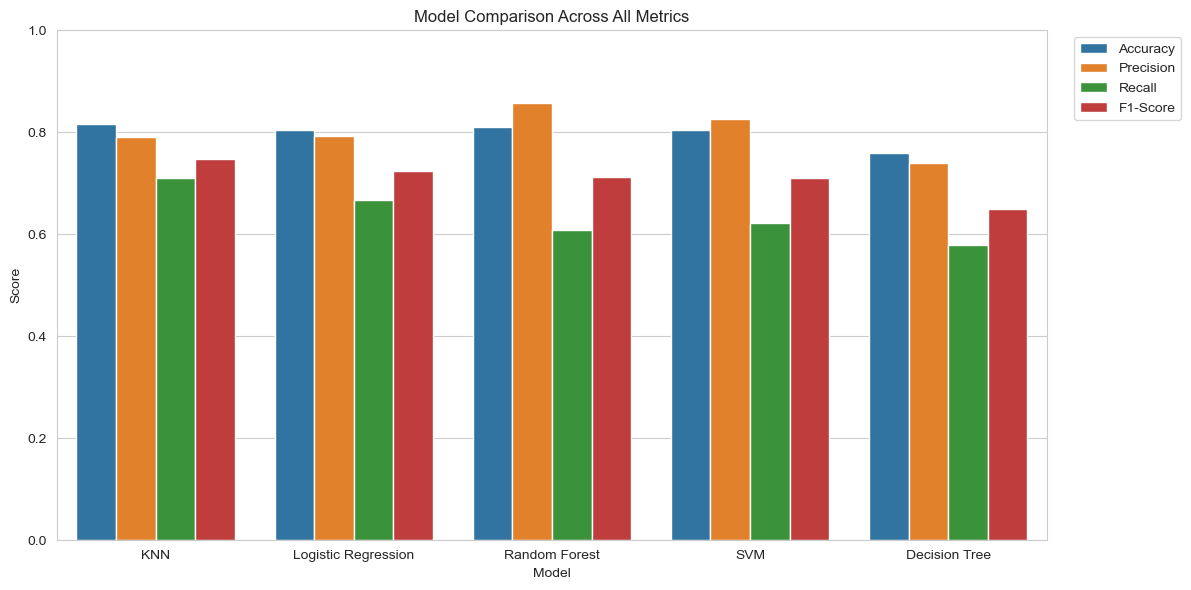

In [21]:
results_melted = results_df.melt(id_vars='Model', var_name='Metric', 
value_name='Score') 
  
plt.figure(figsize=(12, 6)) 
sns.barplot(data=results_melted, x='Model', y='Score', hue='Metric') 
plt.title('Model Comparison Across All Metrics') 
plt.ylim(0, 1) 
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left') 
plt.tight_layout() 
plt.show() 

Task 3 — Look more closely at the confusion matrix for the best-performing model.

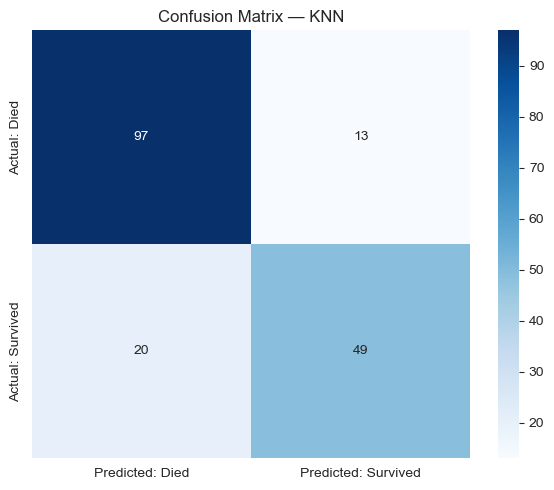

              precision    recall  f1-score   support

        Died       0.83      0.88      0.85       110
    Survived       0.79      0.71      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



In [22]:
best_model_name = results_df.iloc[0]['Model'] 
pred_map = { 
    'Logistic Regression': y_pred_log, 
    'Decision Tree': y_pred_tree, 
    'Random Forest': y_pred_rf, 
    'KNN': y_pred_knn, 
    'SVM': y_pred_svm 
} 
best_preds = pred_map[best_model_name] 
  
cm = confusion_matrix(y_test, best_preds) 
plt.figure(figsize=(6, 5)) 
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted: Died', 'Predicted: Survived'], 
            yticklabels=['Actual: Died', 'Actual: Survived']) 
plt.title(f'Confusion Matrix — {best_model_name}') 
plt.tight_layout() 
plt.show() 
  
print(classification_report(y_test, best_preds, target_names=['Died', 'Survived'])) 

Reading the confusion matrix:  the top-left and bottom-right cells are correct predictions (true negatives and true positives). The top-right cell is passengers the model predicted 
would survive but didn't (false positives), and the bottom-left is passengers it predicted 
would die but who actually survived (false negatives). Which type of mistake matters more 
depends on the application — for a disaster-response system, missing an actual survivor 
(false negative) might be considered worse than a false alarm.

Task 4 — Plot ROC curves for all five models on one chart, and compare their AUC scores. 

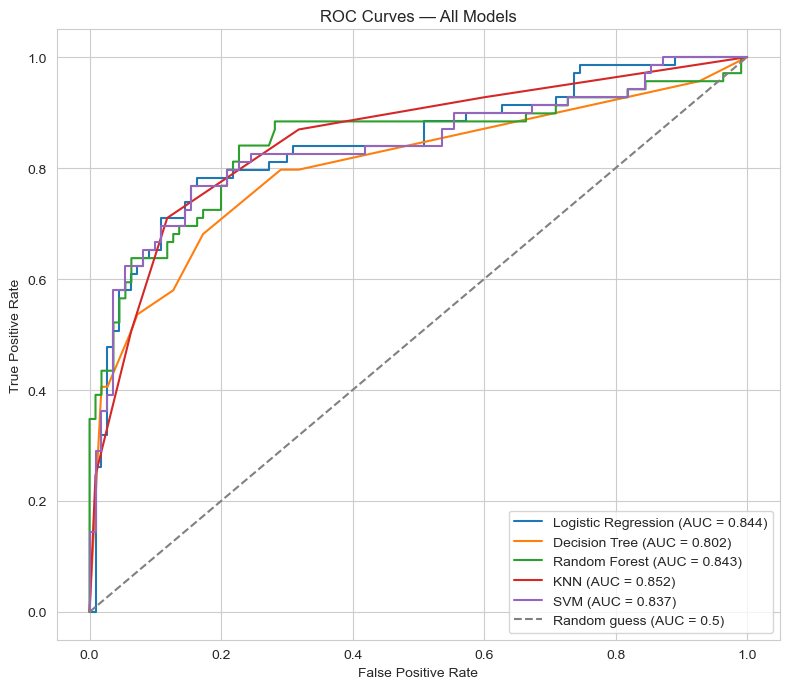

In [23]:
proba_map = { 
'Logistic Regression': log_reg.predict_proba(X_test_scaled)[:, 1], 
'Decision Tree': dec_tree.predict_proba(X_test)[:, 1], 
'Random Forest': rand_forest.predict_proba(X_test)[:, 1], 
'KNN': knn.predict_proba(X_test_scaled)[:, 1], 
'SVM': svm.predict_proba(X_test_scaled)[:, 1] 
} 
plt.figure(figsize=(8, 7)) 
for name, proba in proba_map.items(): 
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess (AUC = 0.5)') 
plt.xlabel('False Positive Rate') 
plt.ylabel('True Positive Rate') 
plt.title('ROC Curves — All Models') 
plt.legend(loc='lower right') 
plt.tight_layout() 
plt.show() 


Observation:  A curve that bows further toward the top-left corner, with a higher AUC, 
separates the two classes better across every possible decision threshold — not just the 
default 0.5 cutoff used for accuracy/precision/recall above. This is why ROC-AUC is often 
reported alongside the threshold-based metrics.

Part 6 — Which Features Mattered Most? 

Task — Use the Random Forest's built-in feature importances to see which passenger attributes 
drove its predictions. 

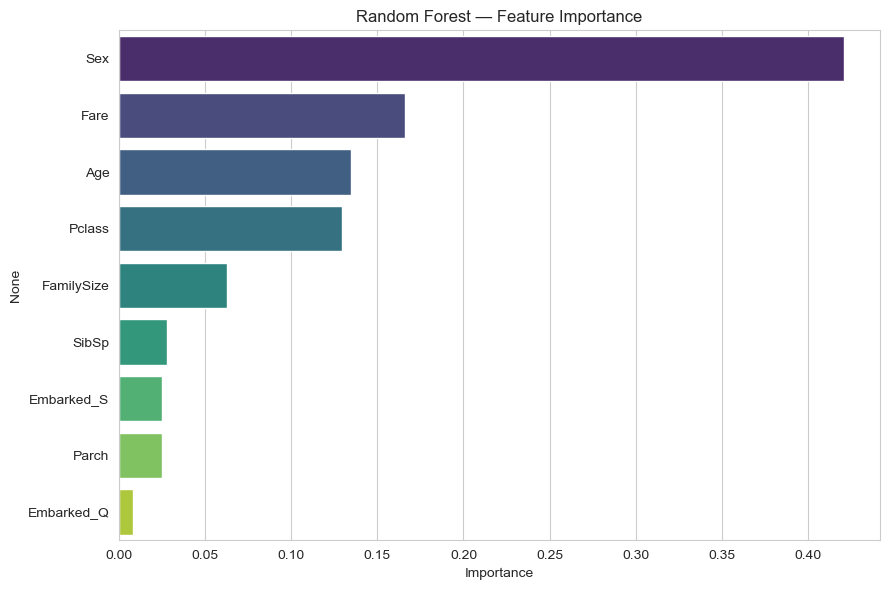

Sex           0.420874
Fare          0.166307
Age           0.134846
Pclass        0.129551
FamilySize    0.062885
SibSp         0.027588
Embarked_S    0.025121
Parch         0.024668
Embarked_Q    0.008161
dtype: float64

In [24]:
importances = pd.Series(rand_forest.feature_importances_, 
index=X.columns).sort_values(ascending=False) 
plt.figure(figsize=(9, 6)) 
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette='viridis', legend=False)
plt.title('Random Forest — Feature Importance') 
plt.xlabel('Importance') 
plt.tight_layout() 
plt.show() 
  
importances 

Observation:  Sex, Fare, and Pclass are typically the strongest predictors — consistent with 
the EDA in Part 1, where sex and passenger class showed the clearest survival gaps. 
FamilySize, the feature we engineered in Part 2, also contributes meaningfully. 

> ## Summary
>
> | Step | What We Did |
> |---|---|
> | Import & Explore | Loaded the Titanic dataset, checked shape/types/missing values, visualized survival by sex, class, and age |
> | Clean & Engineer | Imputed missing `Age`/`Embarked`, dropped unusable columns, encoded categoricals, engineered `FamilySize` |
> | Split & Scale | 80/20 train/test split (stratified), scaled features for distance-based models |
> | Train | Logistic Regression, Decision Tree, Random Forest, KNN, and SVM — all five Module 5 classifiers |
> | Evaluate | Accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC for every model |
> | Interpret | Compared models side by side and examined which features actually drove predictions |
>
> **Takeaway:** No single metric tells the whole story. A model with high accuracy can still miss most of the positive cases if the classes are imbalanced — which is exactly why this lab computed precision, recall, F1, and ROC-AUC alongside accuracy, rather than relying on any one number.